# When does Hyper-Kamiokande match Super-Kamiokande on the DSNB?

NB02 projected the SK-IV analysis to one HK tank. This notebook compares that projection with what SK will have accumulated, including the gadolinium phases, and finds **when HK matches SK**.

"Match" is measured three ways:
1. **Exposure** (kton·yr), the naive answer.
2. **Sensitivity with statistics only**: median Asimov significance for the Horiuchi+09 (6 MeV, max) flux, backgrounds known. This is close to what a spectral fit achieves when the sidebands constrain the atmospheric backgrounds (Sec. 2.2).
3. **Sensitivity with background systematics**, the NB02 treatment: window-only, Gaussian constraints on each background normalisation.

Sources are in `notes/claude/bibliography.md`. Main new inputs:
- SK-Gd DSNB analysis, 956 days ([arXiv:2511.02222](https://arxiv.org/abs/2511.02222)): efficiencies (Table 3), mistag rate (Sec. V.3.3), systematics (Table 5).
- SK press release, Neutrino 2026 (25 June 2026): 3349 days pure water + 1653 days Gd, **2.6σ indication, Φ = 3.6 ± 1.6 cm⁻² s⁻¹ in E_ν = 13.3–81.3 MeV**.

The notebook has three parts:
- **1. SK with gadolinium**
- **2. SK accumulated and its calibration**
- **3. When HK matches SK**

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brentq

from hk_sunu import hk, rates, sk4, skgd, stats
from hk_sunu.flux import DSNBFlux, FermiDirac

INK, MUTED, GRID = "#1f1f1e", "#6b6a63", "#e6e5df"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]
plt.rcParams.update({
    "figure.figsize": (7.2, 4.4), "figure.dpi": 110, "font.size": 11,
    "text.color": INK, "axes.labelcolor": INK, "axes.edgecolor": MUTED,
    "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "lines.linewidth": 2.0, "legend.frameon": False,
})

window = sk4.spectrum()[:11]
HIGH = window["erec_lo"] >= 15.5   # 15.5-29.5 MeV: pure water and HK
MID = window["erec_lo"] >= 11.5    # 11.5-29.5 MeV: SK-Gd (E_nu > 13.3 MeV, as at Neutrino 2026)
REL_PW = np.array([sk4.BACKGROUND_REL_ERROR[key] for key in sk4.BACKGROUNDS])
SK_IV_LIKE = hk.NtagScenario("pure water, SK-IV", 1.0, 1.0)

def dataset(out, mask, rel):
    return out["signal"][mask], np.array([out[key][mask] for key in sk4.BACKGROUNDS]), rel

def z_value(datasets, mode):
    # 'stat' shrinks every background uncertainty to zero; 'syst' keeps them.
    if mode == "stat":
        datasets = [(s, c, r * 1e-4) for s, c, r in datasets]
    return stats.combined_significance(datasets, correlated=True)

# 1. SK with gadolinium

The SK-Gd paper shows its expected backgrounds only in a figure. Each Gd phase is therefore built from SK-IV (Fig. 24) with the rules of NB02 (`skgd.py`):

- signal and real-neutron backgrounds × (SK-Gd efficiency after all cuts, Table 3 NN) / (SK-IV, Fig. 18);
- accidentals × (0.02% per prompt event, NN target) / (SK-IV rate per bin, accidentals over events reaching the tagging step);
- systematics from Table 5: non-NCQE 36% (VI) and 41% (VII), NCQE 71%, ⁹Li 55%, reactor 100%, accidentals 5%.

The SK-IV mistag rate per event is not published; it is inferred bin by bin.

In [2]:
ntag4 = sk4.efficiencies()[:11]["ntag_one"]
mis4 = skgd.sk4_mistag_per_event()
print(f"{'E_rec':>10} {'SK-IV eff':>9} {'VI eff':>7} {'VII eff':>8} {'SK-IV mistag':>13} {'VII/IV acc.':>11}")
for lo, hi, e4, e6, e7, m in zip(window["erec_lo"], window["erec_hi"], ntag4,
                                skgd.EFFICIENCY_NN["SK-VI"], skgd.EFFICIENCY_NN["SK-VII"], mis4):
    print(f"{lo:4.1f}-{hi:4.1f} {e4:9.1f} {e6:7.1f} {e7:8.1f} {m:13.1e} {skgd.MISTAG_PER_EVENT_NN / m:11.3f}")

     E_rec SK-IV eff  VI eff  VII eff  SK-IV mistag VII/IV acc.
 7.5- 9.5       6.4    15.1     21.9       6.3e-04       0.317
 9.5-11.5       8.1    15.9     20.8       7.7e-04       0.261
11.5-13.5      11.3    18.8     27.2       1.5e-03       0.132
13.5-15.5      14.8    26.0     33.4       4.7e-03       0.043
15.5-17.5      13.4    25.5     40.1       1.3e-03       0.157
17.5-19.5      19.8    30.0     45.2       6.4e-03       0.031
19.5-21.5      31.8    32.8     52.4       1.4e-01       0.001
21.5-23.5      31.7    32.3     52.7       1.4e-01       0.001
23.5-25.5      32.0    37.2     55.5       7.5e-02       0.003
25.5-27.5      26.2    36.9     56.1       1.7e-02       0.012
27.5-29.5      26.9    37.1     55.8       2.0e-02       0.010


SK-VII keeps 1.7–3.4 times more signal than SK-IV, and its accidentals are negligible above 15.5 MeV. SK-IV chose loose working points in 19.5–25.5 MeV (mistag up to 14%), where the non-NCQE background dominates anyway.

A check against the paper: SK-Gd states that with twice its 956-day dataset the flux uncertainty would match the ≈ 6000 days of pure water, i.e. one Gd day ≈ 3 pure-water days. The model below gives the ratio of $Z^2$ per day, Gd over pure water.

In [3]:
def sk_datasets(livetimes, gd_mask=MID):
    out = []
    if livetimes.get("pure_water", 0) > 0:
        pw = hk.project(skgd.FIDUCIAL_KTON * livetimes["pure_water"] / 365.25, SK_IV_LIKE, 1.0)
        out.append(dataset(pw, HIGH, REL_PW))
    for phase in ("SK-VI", "SK-VII"):
        if livetimes.get(phase, 0) > 0:
            out.append(dataset(skgd.project(livetimes[phase], phase), gd_mask, skgd.rel_errors(phase)))
    return out

for mode in ("stat", "syst"):
    z_pw = z_value(sk_datasets({"pure_water": 1000.0}), mode)
    z_gd = z_value(sk_datasets({"SK-VII": 1000.0}), mode)
    z_gd_hi = z_value(sk_datasets({"SK-VII": 1000.0}, gd_mask=HIGH), mode)
    print(f"{mode}: Z^2 per day, SK-VII / pure water = {z_gd**2 / z_pw**2:.1f} "
          f"(11.5-29.5 MeV), {z_gd_hi**2 / z_pw**2:.1f} (15.5-29.5 MeV)")

stat: Z^2 per day, SK-VII / pure water = 3.0 (11.5-29.5 MeV), 2.6 (15.5-29.5 MeV)
syst: Z^2 per day, SK-VII / pure water = 1.7 (11.5-29.5 MeV), 1.7 (15.5-29.5 MeV)


With statistics only the model reproduces the factor ≈ 3. With the window-only systematics the gain shrinks, because SK-Gd's non-NCQE uncertainty (≈ 40%) is twice SK-IV's. SK-Gd says the same: above 15.5 MeV the pure-water limits remain the best because of the non-NCQE systematics.

# 2. SK accumulated and its calibration

## 2.1 The SK dataset over time

| Period | Livetime | Treatment |
|---|---|---|
| SK-IV + SK-V, pure water, 2008–2020 | 3349 d | SK-IV, 15.5–29.5 MeV |
| SK-VI, 0.011% Gd | 552 d | SK-VI, 11.5–29.5 MeV |
| SK-VII onward, 0.033% Gd, to June 2026 | 1101 d | SK-VII, 11.5–29.5 MeV |
| After June 2026 | depends on the SK plan, below | SK-VII |

SK-I–III (no neutron tagging) are left out. HK is assumed to start in mid-2028.

The SK run plan after June 2026 is not known to us. Two scenarios:
- **SK-a, no more data**: SK stays at the June 2026 dataset (5002 d), the one of the 2.6σ result.
- **SK-b, data through 2027–2028**: SK keeps running at the 2020–2026 average, ≈ 275 d per calendar year (1653 d in six years), until the end of 2028, and then stops.

In [4]:
SK_PLANS = {"SK-a, no more data": 2026.5, "SK-b, data to end of 2028": 2029.0}
z_sk = {}
for label, year in SK_PLANS.items():
    lt = skgd.livetimes_at(year)
    total = sum(lt.values())
    z_sk[label] = {mode: z_value(sk_datasets(lt), mode) for mode in ("stat", "syst")}
    print(f"{label:26}: {total:5.0f} d, {skgd.FIDUCIAL_KTON * total / 365.25:4.0f} kton yr, "
          f"Z = {z_sk[label]['stat']:.2f} (stat), {z_sk[label]['syst']:.2f} (syst)")
print(f"{'SK-I-IV, 5823 d':26}: {skgd.FIDUCIAL_KTON * 5823 / 365.25:4.0f} kton yr")

SK-a, no more data        :  5002 d,  308 kton yr, Z = 1.94 (stat), 1.28 (syst)
SK-b, data to end of 2028 :  5691 d,  351 kton yr, Z = 2.19 (stat), 1.34 (syst)
SK-I-IV, 5823 d           :  359 kton yr


## 2.2 Calibration with the Neutrino 2026 result

The signal in this model is the Horiuchi+09 (6 MeV, max) spectrum of SK-IV Fig. 24. Integrated over E_ν = 13.3–81.3 MeV, as in the press release, that model gives about 3.8 cm⁻² s⁻¹ (below). SK measured **3.6 ± 1.6**, so the assumed signal is close to the SK best fit, and SK's expected significance for it is roughly 3.8 / 1.6 ≈ 2.4σ.

In [5]:
fl = DSNBFlux(FermiDirac(6.0))
ratio = rates.integrated_flux(fl, 13.3, 81.3) / rates.integrated_flux(fl, 17.3, 100.0)
phi = sk4.HORIUCHI09_FLUX * ratio
print(f"Horiuchi+09 6 MeV max: {sk4.HORIUCHI09_FLUX} (E_nu > 17.3) x {ratio:.2f} = {phi:.1f} cm^-2 s^-1 (13.3-81.3 MeV)")
print(f"SK June 2026 expected for this flux: ~{phi / 1.6:.1f} sigma (from the quoted +-1.6)")
za = z_sk["SK-a, no more data"]
print(f"This model, June 2026: {za['stat']:.2f} (stat), {za['syst']:.2f} (syst)")

Horiuchi+09 6 MeV max: 1.94 (E_nu > 17.3) x 1.97 = 3.8 cm^-2 s^-1 (13.3-81.3 MeV)
SK June 2026 expected for this flux: ~2.4 sigma (from the quoted +-1.6)
This model, June 2026: 1.94 (stat), 1.28 (syst)


**The statistics-only treatment is the one that tracks SK's real analysis** (1.9σ against ≈ 2.4σ). The window-only systematic treatment underestimates it by a factor of ≈ 2. The real fit extends to 79.5 MeV and uses the multi-neutron samples, which constrain the atmospheric normalisation (10% in the Neutrino 2026 fit according to [arXiv:2609.17705](https://arxiv.org/abs/2609.17705), App. C). So in Sec. 3 the statistics-only case is the **reference**, and the systematic case is a pessimistic bound.

The observed 2.6σ is consistent with an upward fluctuation of ≈ 0.2–0.7σ on top of the expected significance.

# 3. When HK matches SK

HK scenarios from NB02, with $f_{sp} = 6.5$ and the window 15.5–29.5 MeV:

| | Tagging | Systematics |
|---|---|---|
| A, SK-IV-like | SK-IV | SK-IV |
| B, degraded | 0.75 × SK-IV, 3 × accidentals | SK-IV |
| C, pessimistic | 0.5 × SK-IV, 10 × accidentals | SK-IV |
| G*, SK-Gd-like (**not an HK scenario**) | SK-VII efficiency and mistag | SK-VII |

**HK will not be loaded with Gd: neutrons are tagged only through capture on hydrogen** (2.2 MeV γ, ≈ 200 µs). A–C are the HK scenarios. The trigger study with HK's simulation ([arXiv:2605.31391](https://arxiv.org/abs/2605.31391), ≤ 25% for an isolated 2.2 MeV γ) points to B–C rather than A, so **A is optimistic**.

G* is kept only as a reference: it is what [arXiv:2609.17705](https://arxiv.org/abs/2609.17705) assumes for HK ("similar neutron-tagging capabilities" to SK-Gd), and it shows how much that assumption is worth. It is drawn dashed. Scenario D of NB02 (DR tagging, 40% coverage) is dropped.

HK duty factor: 80% (SK-IV had 81%).

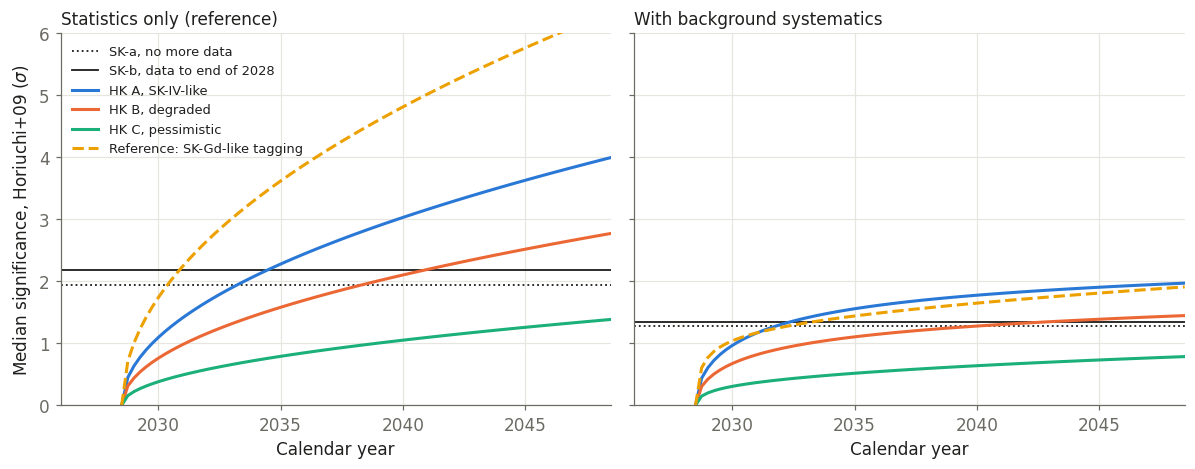

In [6]:
vii = skgd.scenario("SK-VII")
HK_SCEN = {
    "A": (hk.NtagScenario("A, SK-IV-like", 1.0, 1.0), REL_PW),
    "B": (hk.NtagScenario("B, degraded", 0.75, 3.0), REL_PW),
    "C": (hk.NtagScenario("C, pessimistic", 0.5, 10.0), REL_PW),
    "G": (hk.NtagScenario("G*, SK-Gd-like", vii.efficiency_scale, vii.mistag_scale), skgd.rel_errors("SK-VII")),
}
F_SP, DUTY, HK_START = 6.5, 0.8, 2028.5

def z_hk(key, live_years, mode, f_sp=F_SP):
    scen, rel = HK_SCEN[key]
    out = hk.project(live_years * hk.FIDUCIAL_KTON, scen, f_sp)
    return z_value([dataset(out, HIGH, rel)], mode)

def z_sk_at(year, mode):
    return z_value(sk_datasets(skgd.livetimes_at(year)), mode)

def crossing(f, lo=0.05, hi=40.0):
    try:
        return brentq(f, lo, hi)
    except ValueError:
        return np.nan

years = np.linspace(HK_START, 2048.5, 81)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), sharey=True)
for ax, mode, title in zip(axes, ("stat", "syst"), ("Statistics only (reference)", "With background systematics")):
    for (label, _), ls in zip(SK_PLANS.items(), (":", "-")):
        ax.axhline(z_sk[label][mode], color=INK, ls=ls, lw=1.2, label=label)
    for (key, (scen, _)), color in zip(HK_SCEN.items(), SERIES):
        ax.plot(years, [z_hk(key, DUTY * (y - HK_START), mode) for y in years], color=color,
                ls="--" if key == "G" else "-", label=f"HK {scen.name}" if key != "G" else "Reference: SK-Gd-like tagging")
    ax.set(xlim=(2026, 2048.5), ylim=(0, 6), xlabel="Calendar year", xticks=range(2030, 2050, 5))
    ax.set_title(title, loc="left", fontsize=11)
axes[0].set_ylabel("Median significance, Horiuchi+09 ($\\sigma$)")
axes[0].legend(loc="upper left", fontsize=8.5)
fig.tight_layout()

In [7]:
print("HK livetime years (calendar date) to match SK")
print(f"{'':16}" + "".join(f"{label.split(',')[0] + ', ' + mode:>22}" for label in SK_PLANS for mode in ("stat", "syst")))
for key, (scen, _) in HK_SCEN.items():
    row = f"{scen.name:16}"
    for label in SK_PLANS:
        for mode in ("stat", "syst"):
            t = crossing(lambda t: z_hk(key, t, mode) - z_sk[label][mode], hi=80.0)
            row += f"{t:12.1f} ({HK_START + t / DUTY:6.1f})" if t < 30 else f"{'never (> 30 yr)':>22}"
    print(row)
print("(G* is not an HK scenario: HK tags neutrons on hydrogen only)\n")

for label, year in SK_PLANS.items():
    exposure = skgd.FIDUCIAL_KTON * sum(skgd.livetimes_at(year).values()) / 365.25
    print(f"Exposure, {label}: {exposure:.0f} kton yr -> HK matches it in {exposure / hk.FIDUCIAL_KTON:.1f} livetime years "
          f"({HK_START + exposure / hk.FIDUCIAL_KTON / DUTY:.1f})")

HK livetime years (calendar date) to match SK
                            SK-a, stat            SK-a, syst            SK-b, stat            SK-b, syst


A, SK-IV-like            3.8 (2033.2)         2.6 (2031.8)         4.8 (2034.5)         3.0 (2032.3)


B, degraded              7.8 (2038.3)         9.3 (2040.1)        10.0 (2040.9)        11.2 (2042.5)


C, pessimistic         never (> 30 yr)       never (> 30 yr)       never (> 30 yr)       never (> 30 yr)


G*, SK-Gd-like           1.5 (2030.4)         3.1 (2032.3)         1.9 (2030.9)         3.7 (2033.2)
(G* is not an HK scenario: HK tags neutrons on hydrogen only)

Exposure, SK-a, no more data: 308 kton yr -> HK matches it in 1.6 livetime years (2030.6)
Exposure, SK-b, data to end of 2028: 351 kton yr -> HK matches it in 1.9 livetime years (2030.8)


## 3.1 If HK starts later

In both SK scenarios SK has stopped by the start of 2029, so a later HK start does not raise the target: **the crossing date moves one to one with the HK start.** (If SK kept running until HK started, each year of delay would move the crossing by ≈ 1.5 years in A.)

## 3.2 Why HK is only ~2 SK-Gd per year, not 8

Per livetime year, HK has 8.3 times the fiducial mass of SK. Its per-year gain in $Z^2$ over SK-Gd is much smaller:

In [8]:
z2_sk_year = z_value(sk_datasets({"SK-VII": skgd.GD_DAYS_PER_YEAR}), "stat") ** 2
for key, (scen, _) in HK_SCEN.items():
    z2 = z_hk(key, DUTY, "stat") ** 2
    print(f"HK {scen.name:16}: Z^2 per calendar year = {z2:.2f}, {z2 / z2_sk_year:4.1f} x SK-Gd ({z2_sk_year:.2f})")

HK A, SK-IV-like   : Z^2 per calendar year = 0.80,  2.0 x SK-Gd (0.40)
HK B, degraded     : Z^2 per calendar year = 0.38,  1.0 x SK-Gd (0.40)
HK C, pessimistic  : Z^2 per calendar year = 0.10,  0.2 x SK-Gd (0.40)
HK G*, SK-Gd-like  : Z^2 per calendar year = 2.02,  5.0 x SK-Gd (0.40)


In [9]:
# Breakdown of the HK-A / SK-Gd factor, statistics only, per calendar year
mass = hk.FIDUCIAL_KTON / skgd.FIDUCIAL_KTON
duty = DUTY / (skgd.GD_DAYS_PER_YEAR / 365.25)
z2_vii_hi = z_value(sk_datasets({"SK-VII": skgd.GD_DAYS_PER_YEAR}, gd_mask=HIGH), "stat") ** 2
window_gain = z2_sk_year / z2_vii_hi
z2_pw = z_value(sk_datasets({"pure_water": skgd.GD_DAYS_PER_YEAR}), "stat") ** 2
tagging = z2_pw / z2_vii_hi
spall = z_hk("A", DUTY, "stat") ** 2 / z_hk("A", DUTY, "stat", f_sp=1.0) ** 2
print(f"mass {mass:.1f} x duty {duty:.2f} x tagging (SK-IV / SK-VII) {tagging:.2f} "
      f"x spallation cut {spall:.2f} / SK-Gd window below 15.5 MeV {window_gain:.2f} "
      f"= {mass * duty * tagging * spall / window_gain:.1f}")

mass 8.3 x duty 1.06 x tagging (SK-IV / SK-VII) 0.38 x spallation cut 0.68 / SK-Gd window below 15.5 MeV 1.16 = 2.0


The factor of 8 in mass becomes ≈ 2 because of, in order of importance:
- **neutron tagging**: per unit exposure above 15.5 MeV, pure-water SK-IV tagging gives ≈ 0.4 of the SK-Gd $Z^2$;
- **the efficiency of the spallation cut** at the shallower site, in 15.5–23.5 MeV;
- **the closed window below 15.5 MeV**, which costs less than expected: SK-Gd gets only ≈ 15% of its $Z^2$ from 11.5–15.5 MeV in this model.

# 4. Conclusions

- **Exposure:** SK has 308 kton·yr (June 2026) and would have ≈ 350 by the end of 2028. HK matches that in **≈ 1.6–1.9 livetime years**, i.e. in the second half of 2030. This number says little about the physics reach.
- **Sensitivity, reference case (statistics only, which tracks the real SK fit):** HK, tagging on hydrogen only, matches SK after **≈ 4–5 livetime years in A (2033–34), ≈ 8–10 in B (2038–41) and never in practice in C**; the lower values are for SK-a (no more data), the higher for SK-b (data to end of 2028). A is optimistic; the trigger study points to B–C.
- **The ≈ 5σ in 10 years of arXiv:2609.17705 assumes SK-Gd-like tagging (G*), which HK will not have.** With that assumption HK would match SK in 1.8 years; without it, 4.6 years at best.
- **With window-only systematics** everything saturates near 1.3–2σ, and the comparison depends on the systematic assumptions more than on the detectors. Reducing the atmospheric uncertainties with a spectral fit and sidebands is what makes HK's statistics useful.
- **HK's DSNB reach hinges on neutron tagging on hydrogen with 20% coverage.** Even scenario A gains only ≈ 2 times SK-Gd per year, B about the same as SK-Gd, C a fifth. In the realistic range (B–C), **HK alone does not clearly beat SK-Gd on the DSNB for about a decade**; the gain must come from the tagging (ROC working point, timing, the neutron cloud) and from the systematics.

Caveats:
- SK-Gd is modelled by scaling SK-IV, not from its published per-bin expectations (only in a figure).
- The HK start (mid-2028), the HK duty factor (80%) and the two SK run plans are assumptions.
- The signal is Horiuchi+09 (6 MeV, max), which is close to the SK best fit of June 2026. For a smaller flux, the statistics-only crossing times do not change at first order (both detectors scale alike in $S^2/B$ when $S \ll B$), but the significances drop.